# 02 · สรุปทุก window 10 s

รวม 20 แถวเป็น 1 window แล้วใช้สถิติของกล้องและประตูใน window นั้น label = `max(power_on)` ใน window

ทุกโมเดลใช้ Pipeline เดียวกัน: `SimpleImputer(median) → StandardScaler → classifier`

In [1]:
import numpy as np, pandas as pd
train = pd.read_csv("../../data/train.csv")   # วันที่ 1–3
test = pd.read_csv("../../data/test.csv")     # วันที่ 4

In [2]:
def windows(df):
    """รวมทุก 20 แถว (10 s) ต่อ (day, boot) แล้วตัด warm-up 3 นาทีแรก (18 window)"""
    out = []
    for _, s in df.groupby(["day", "boot"], sort=False):
        s = s.assign(cam=s.person_count.where(s.person_count >= 0),                       # -1 = กล้องไม่ส่ง
                     door=((s.digital_do == 0) | (s.analog_2_raw > 1000)).astype(int),   # IR หรือ gray เห็นวัตถุที่ประตู
                     win=np.arange(len(s)) // 20)
        g = s.groupby("win")
        w = pd.DataFrame({
            "day": g.day.first(), "boot": g.boot.first(), "n": g.size(), "label": g.power_on.max(),
            "cam_max": g.cam.max(), "cam_mean": g.cam.mean(),
            "cam_pos_frac": g.cam.apply(lambda x: (x.dropna() > 0).mean() if x.notna().any() else np.nan),
            "cam_missing_frac": g.cam.apply(lambda x: x.isna().mean()),
            "door_any": g.door.max(),
            "door_events": g.door.apply(lambda x: int((x.diff() == 1).sum() + x.iloc[0])),
            "temp": g.temp_c.mean(), "hum": g.humidity.mean(), "mq2": g.mq2_raw.median(), "ldr": g.analog_1_raw.mean(),
        }).reset_index()
        out.append(w)
    W = pd.concat(out, ignore_index=True)
    return W[(W.n == 20) & ~((W.boot == 0) & (W.win < 18))].reset_index(drop=True)

tr, te = windows(train), windows(test)
F = ["cam_max", "cam_mean", "cam_pos_frac", "cam_missing_frac", "door_any", "door_events"]
Xtr, ytr, days = tr[F], tr.label, tr.day
Xte, yte = te[F], te.label
Xtr.shape, Xte.shape

((3182, 6), (1061, 6))

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.metrics import f1_score, recall_score, precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "DecisionTree": DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, class_weight="balanced", random_state=0),
    "RandomForest": RandomForestClassifier(50, max_depth=6, min_samples_leaf=5, class_weight="balanced", random_state=0, n_jobs=-1),
    "KNN": KNeighborsClassifier(15),
    "GaussianNB": GaussianNB(),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=4, class_weight="balanced", random_state=0),
}
res, preds = [], {}   # preds = ผลทำนาย test ของแต่ละโมเดล (ใช้ใน 05_compare)
for name, clf in models.items():
    pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("clf", clf)])
    # เลือกโมเดลด้วย leave-one-day-out บน train เท่านั้น ส่วน test (วันที่ 4) ดูครั้งเดียว
    cv = cross_val_score(pipe, Xtr, ytr, groups=days, cv=LeaveOneGroupOut(), scoring="f1")
    p = preds[name] = pipe.fit(Xtr, ytr).predict(Xte)
    res.append(dict(model=name, cv_f1=cv.mean(), test_f1=f1_score(yte, p),
                    test_recall=recall_score(yte, p), test_precision=precision_score(yte, p)))
res = pd.DataFrame(res).sort_values("cv_f1", ascending=False).round(4)
res

,model,cv_f1,test_f1,test_recall,test_precision
4,GaussianNB,0.9632,0.9539,0.9590,0.9489
2,RandomForest,0.9625,0.9530,0.9559,0.9502
1,DecisionTree,0.9622,0.9530,0.9559,0.9502
5,HistGradientBoosting,0.9611,0.9530,0.9559,0.9502
3,KNN,0.9595,0.9539,0.9590,0.9489
0,LogisticRegression,0.9586,0.9546,0.9590,0.9503


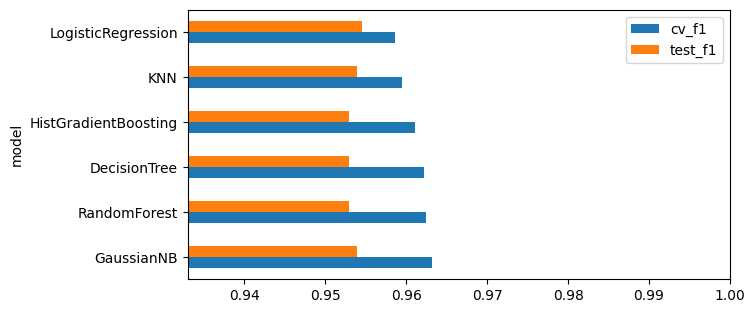

In [4]:
res.set_index("model")[["cv_f1", "test_f1"]].plot.barh(figsize=(7, 3.5), xlim=(res[["cv_f1", "test_f1"]].min().min() - 0.02, 1));